# Imatinib unbinding from Abl kinase (2HYY)

200 PathGennie unbinding trajectories. Labels: the three routes of the PathGennie study — Path I (P-loop/hinge),
Path II (αC/catalytic loop), Path III (C-lobe) — with Path III divided into two adjacent branches IIIa and IIIb,
and two outlier trajectories. FDM on the imatinib coordinates: L² distance, σ = median, α = 0.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]          # repository root (notebook lives in systems/<name>/)
sys.path[:0] = [str(ROOT), str(Path.cwd())]
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathfdm import embed
from pathfdm.features import feature_matrix
from pathfdm.surrogate import fit_surrogate
from pathfdm.evaluation import auc_per_coordinate, kmeans_ari, align_signs, compare_embeddings
from pathfdm.plotting import apply_style, plot_space, plot_parity, plot_beeswarm
import load_data as D
apply_style()
N_JOBS = 8
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

In [2]:
ts, labels = D.load(n_jobs=N_JOBS)
{D.LABEL_CONFIG[k]['name']: int((labels == k).sum()) for k in D.LABEL_CONFIG}

200 trajectories | 68 solute atoms + 0 water oxygens | 154-524 frames | 204 coordinates per frame


{'Path I': 46,
 'Path II': 72,
 'Path IIIa': 38,
 'Path IIIb': 42,
 'Outlier 1': 1,
 'Outlier 2': 1}

## FDM embedding

sigma = 175.05


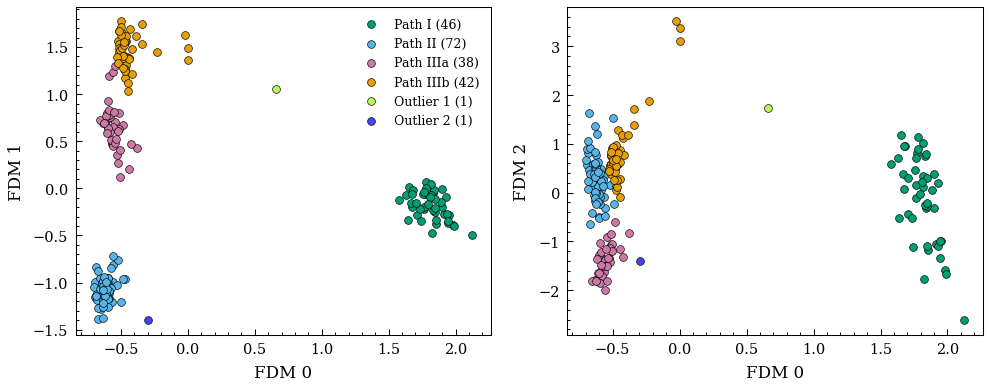

In [3]:
Z, model = embed(ts.fd, metric="l2", return_model=True, n_jobs=N_JOBS)
print(f"sigma = {model.sigma_:.2f}")
fig, axs = plt.subplots(1, 2, figsize=(6.8, 2.8))
plot_space(Z, labels, D.LABEL_CONFIG, ax=axs[0]); plot_space(Z, labels, D.LABEL_CONFIG, dims=(0, 2), ax=axs[1], legend=False)
plt.tight_layout(); plt.show()

## Agreement with the routes

In [4]:
ok = labels >= 0
p4 = KMeans(4, n_init=20, random_state=0).fit_predict(Z[:, :3])
print(f"k-means (k = 4) on FDM 0-2: ARI = {adjusted_rand_score(labels, p4):.3f} (all), "
      f"{adjusted_rand_score(labels[ok], p4[ok]):.3f} (outliers left out)")
coarse = np.where(np.isin(labels, [0, 3]), 3, labels)
p3 = KMeans(3, n_init=20, random_state=0).fit_predict(Z[ok, :3])
print(f"k-means (k = 3), Paths I-III: ARI = {adjusted_rand_score(coarse[ok], p3):.3f} (outliers left out)")
from scipy.spatial.distance import cdist
d = cdist(Z[:, :2], Z[:, :2]); np.fill_diagonal(d, np.inf); nn = d.min(1)
for k in (-1, -2):
    print(f"{D.LABEL_CONFIG[k]['name']}: nearest-neighbour distance {nn[labels == k][0]:.2f} (median {np.median(nn):.3f})")

k-means (k = 4) on FDM 0-2: ARI = 0.985 (all), 1.000 (outliers left out)
k-means (k = 3), Paths I-III: ARI = 1.000 (outliers left out)
Outlier 1: nearest-neighbour distance 0.72 (median 0.024)
Outlier 2: nearest-neighbour distance 0.27 (median 0.024)
